# <center> <span style="color:red"> M1 - Financial Econometrics with Python <span/> <center>
## <center> Midterm 2025-2026 <center> 
### <center> <span style="color:blue"> Group members: Loup KASSIS - 110776 (Cohort C) / Sohel HALLIL - 101475 (Cohort C) / Alexandre MAGNAN- 105344 (Cohort C) <center>


In [80]:
!pip install yfinance

In [83]:
import pandas as pd
import numpy as np
import yfinance as yf
import matplotlib.pyplot as plt

import statsmodels.api as sm
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.stats.diagnostic import acorr_ljungbox

from scipy.stats import skew, kurtosis, jarque_bera

plt.rcParams["figure.figsize"] = (8,4)

### Preliminary Steps

In [110]:
import pandas as pd
import numpy as np
import yfinance as yf
import matplotlib.pyplot as plt

from scipy.stats import skew, kurtosis, jarque_bera
from statsmodels.stats.diagnostic import lilliefors  # Lilliefors normality test

# Set default plot style
plt.rcParams["figure.figsize"] = (9,4)
plt.rcParams["axes.grid"] = True

# Yahoo Finance ticker for the Swiss Market Index (SMI)
ticker = "^SSMI"
start = "1999-01-01"          # Start date chosen to ensure ≥ 25 years of data
end   = "2024-12-31"          # End date covering all of 2024

# Download price data from Yahoo Finance
data = yf.download(ticker, start=start, end=end)

# Extract first and last available dates
first_date = prices.index.min()
last_date  = prices.index.max()

# Daily log returns
ret_d = np.log(prices / prices.shift(1)).dropna()

# Weekly log returns using last observation of each Friday
prices_w = prices.resample("W-FRI").last()
ret_w = np.log(prices_w / prices_w.shift(1)).dropna()

# Monthly log returns using last trading day of each month
prices_m = prices.resample("M").last()
ret_m = np.log(prices_m / prices_m.shift(1)).dropna()

# Annual log returns using last trading day of each year
prices_y = prices.resample("Y").last()
ret_y = np.log(prices_y / prices_y.shift(1)).dropna()

print(f"Name and exact ticker : Swiss Market Index (SMI), Yahoo ticker {ticker}")
print("Length of the sample  :")
print(f" - {len(prices)} daily observations (prices)")
print(f" - {len(prices_w)} weekly observations (prices)")
print(f" - {len(prices_m)} monthly observations (prices)")
print(f" - {len(prices_y)} yearly observations (prices)")
print(f"Initial date          : {first_date.date()}")
print(f"Final date            : {last_date.date()}")
print("Stock market & country: SIX Swiss Exchange (Zurich), SWITZERLAND")


def make_stats_for_course(x):

    # Ensure x is a pandas Series
    if isinstance(x, pd.DataFrame):
        x = x.iloc[:, 0]

    # Convert returns to percent
    x = x * 100.0
    n = int(len(x))

    # Mean and standard deviation
    mean_  = float(x.mean())
    std_   = float(x.std())

    # Diameter of 95% confidence interval for the mean: ±1.96 * σ / sqrt(n)
    ci_diam = float(1.96 * std_ / np.sqrt(n))

    # Higher-order moments
    skew_   = float(skew(x))
    kurt_   = float(kurtosis(x, fisher=False))  # "Normal" kurtosis (3 for Gaussian)
    ex_kurt = float(kurtosis(x, fisher=True))   # Excess kurtosis (0 for Gaussian)

    # Basic distribution quantiles
    min_ = float(x.min())
    q5   = float(x.quantile(0.05))
    q25  = float(x.quantile(0.25))
    med  = float(x.median())
    q75  = float(x.quantile(0.75))
    q95  = float(x.quantile(0.95))
    max_ = float(x.max())

    # Jarque–Bera normality test
    jb_stat, jb_p = jarque_bera(x)
    jb_stat = float(jb_stat)
    jb_p    = float(jb_p)

    # Lilliefors test for normality (KS test with estimated mean and std)
    lillie_stat, lillie_p = lilliefors(x)
    lillie_stat = float(lillie_stat)
    lillie_p    = float(lillie_p)

    # Return all statistics as a named Series
    return pd.Series({
        "Mean": mean_,
        "St.Deviation": std_,
        "Diameter.C.I.Mean": ci_diam,
        "Skewness": skew_,
        "Kurtosis": kurt_,
        "Excess.Kurtosis": ex_kurt,
        "Min": min_,
        "Quant.5%": q5,
        "Quant.25%": q25,
        "Median.50%": med,
        "Quant.75%": q75,
        "Quant.95%": q95,
        "Max": max_,
        "Jarque.Bera.stat": jb_stat,
        "Jarque.Bera.pvalue": jb_p,
        "Lillie.test.stat": lillie_stat,
        "Lillie.test.pvalue": lillie_p,
        "N.obs": n
    })

# Build the summary statistics table for all return frequencies
table = pd.DataFrame({
    "Daily":   make_stats_for_course(ret_d),
    "Weekly":  make_stats_for_course(ret_w),
    "Monthly": make_stats_for_course(ret_m),
    "Annual":  make_stats_for_course(ret_y),
})

display(table)

prices.plot(title="Swiss Market Index (^SSMI) — Daily prices")
plt.show()

/var/folders/sh/xy8x7lwj1kg1ffmgpdrrvdvh0000gn/T/ipykernel_30124/2103020087.py:19: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(ticker, start=start, end=end)
[*********************100%***********************]  1 of 1 completed

Name and exact ticker : Swiss Market Index (SMI), Yahoo ticker ^SSMI
Length of the sample  :
 - 312 daily observations (prices)
 - 1353 weekly observations (prices)
 - 312 monthly observations (prices)
 - 26 yearly observations (prices)
Initial date          : 1999-01-31
Final date            : 2024-12-31
Stock market & country: SIX Swiss Exchange (Zurich), SWITZERLAND



/var/folders/sh/xy8x7lwj1kg1ffmgpdrrvdvh0000gn/T/ipykernel_30124/2103020087.py:33: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  prices_m = prices.resample("M").last()
/var/folders/sh/xy8x7lwj1kg1ffmgpdrrvdvh0000gn/T/ipykernel_30124/2103020087.py:37: FutureWarning: 'Y' is deprecated and will be removed in a future version, please use 'YE' instead.
  prices_y = prices.resample("Y").last()
/var/folders/sh/xy8x7lwj1kg1ffmgpdrrvdvh0000gn/T/ipykernel_30124/2103020087.py:69: SmallSampleWarning: One or more sample arguments is too small; all returned values will be NaN. See documentation for sample size requirements.
  skew_   = float(skew(x))
/var/folders/sh/xy8x7lwj1kg1ffmgpdrrvdvh0000gn/T/ipykernel_30124/2103020087.py:70: SmallSampleWarning: One or more sample arguments is too small; all returned values will be NaN. See documentation for sample size requirements.
  kurt_   = float(kurtosis(x, fisher=False))  # "Normal" kurtosis (3 for

ValueError: Test for distribution norm requires at least 4 observations

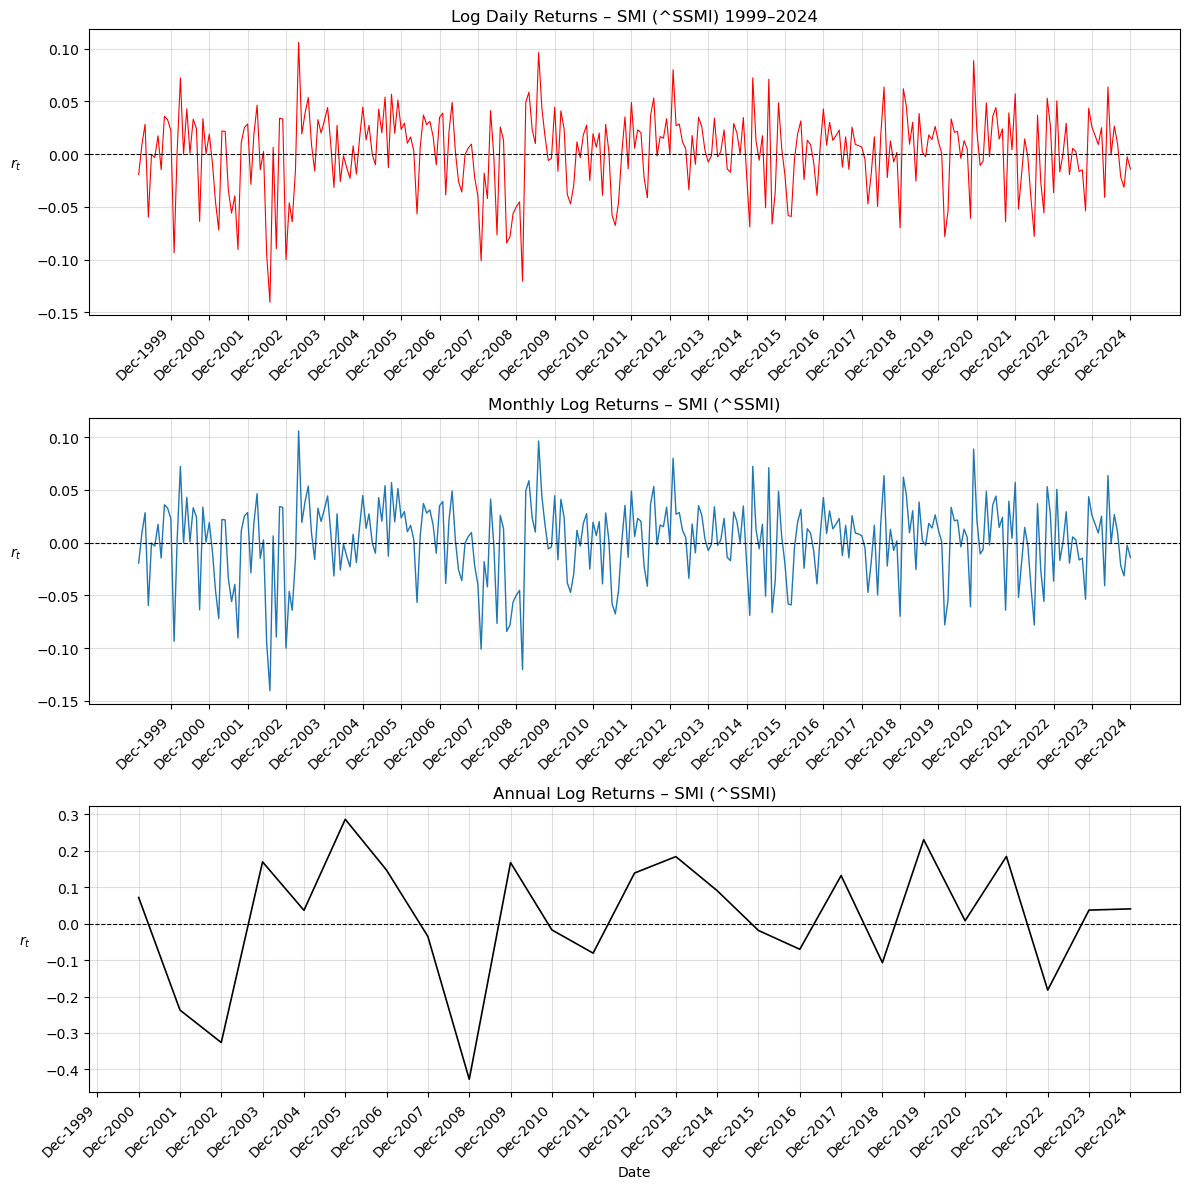

In [88]:
# Define start and end years for x-axis labels (ensures coverage from 1999 onward)
year_start = max(first_date.year, 1999)
year_end   = last_date.year

# Create year-end date labels (Dec 31 of each year)
date_labels = pd.date_range(start=f"{year_start}-12-31",
                            end=f"{year_end}-12-31", freq="YE-DEC")

# Format labels as "Dec-YYYY" for readability
formatted_labels = [f"Dec-{d.year}" for d in date_labels]

# Create a 3-panel figure for daily, monthly, and annual returns
fig, axs = plt.subplots(3, 1, figsize=(12, 12), sharex=False)

# -----------------------------------------
#               DAILY RETURNS
# -----------------------------------------
axs[0].plot(ret_d.index, ret_d, color="red", lw=0.8)   # Daily log returns
axs[0].axhline(y=0, color="black", linestyle="--", lw=0.8)  # Zero-return baseline
axs[0].set_title("Log Daily Returns – SMI (^SSMI) 1999–2024")
axs[0].set_ylabel(r"$r_t$", rotation=0, labelpad=15)   # LaTeX-style label
axs[0].grid(True, alpha=0.4)
axs[0].set_xticks(date_labels)                         # Year-end ticks
axs[0].set_xticklabels(formatted_labels, rotation=45, ha="right")

# -----------------------------------------
#              MONTHLY RETURNS
# -----------------------------------------
axs[1].plot(ret_m.index, ret_m, color="tab:blue", lw=1.0)  # Monthly log returns
axs[1].axhline(y=0, color="black", linestyle="--", lw=0.8)
axs[1].set_title("Monthly Log Returns – SMI (^SSMI)")
axs[1].set_ylabel(r"$r_t$", rotation=0, labelpad=15)
axs[1].grid(True, alpha=0.4)
axs[1].set_xticks(date_labels)
axs[1].set_xticklabels(formatted_labels, rotation=45, ha="right")

# -----------------------------------------
#               ANNUAL RETURNS
# -----------------------------------------
axs[2].plot(ret_y.index, ret_y, color="black", lw=1.2)  # Annual log returns
axs[2].axhline(y=0, color="black", linestyle="--", lw=0.8)
axs[2].set_title("Annual Log Returns – SMI (^SSMI)")
axs[2].set_xlabel("Date")
axs[2].set_ylabel(r"$r_t$", rotation=0, labelpad=15)
axs[2].grid(True, alpha=0.4)
axs[2].set_xticks(date_labels)
axs[2].set_xticklabels(formatted_labels, rotation=45, ha="right")

# Adjust layout to prevent overlapping elements
plt.tight_layout()

# Display the final plot
plt.show()


# Question 1
### Stylized Fact 2 : Returns are stationnary

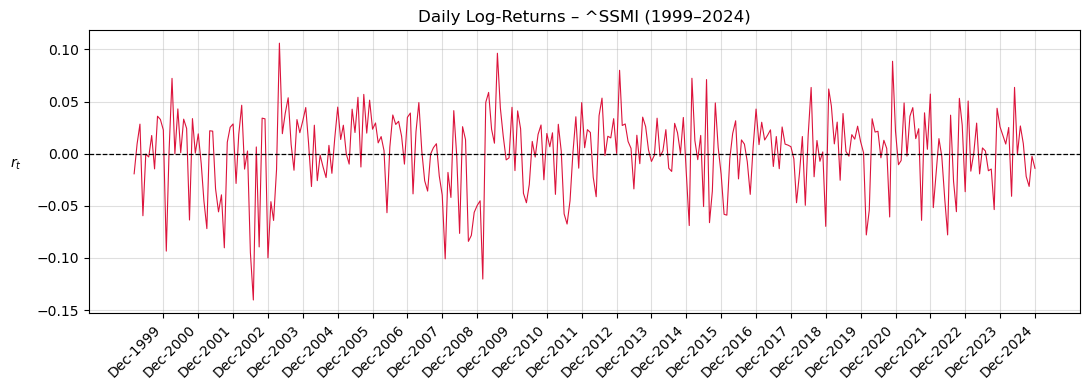

In [89]:
# Daily log-returns around zero
date_labels = pd.date_range(start=f"{max(first_date.year, 1999)}-12-31",
                            end=f"{last_date.year}-12-31", freq="YE-DEC")
formatted_labels = [f"Dec-{d.year}" for d in date_labels]

plt.figure(figsize=(11,4))
plt.plot(ret_d.index, ret_d, color="crimson", lw=0.8)
plt.axhline(0, color="black", ls="--", lw=0.9)
plt.title("Daily Log-Returns – ^SSMI (1999–2024)")
plt.ylabel(r"$r_t$", rotation=0, labelpad=15)
plt.xticks(date_labels, formatted_labels, rotation=45, ha="right")
plt.grid(True, alpha=0.4)
plt.tight_layout()
plt.show()


/var/folders/sh/xy8x7lwj1kg1ffmgpdrrvdvh0000gn/T/ipykernel_30124/3717718199.py:9: FutureWarning: YF.download() has changed argument auto_adjust default to True
  smi = yf.download("^SSMI", start="1999-01-01", end="2024-12-31", progress=False)
/var/folders/sh/xy8x7lwj1kg1ffmgpdrrvdvh0000gn/T/ipykernel_30124/3717718199.py:29: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  alpha = float(reg.intercept_)                      # estimated intercept


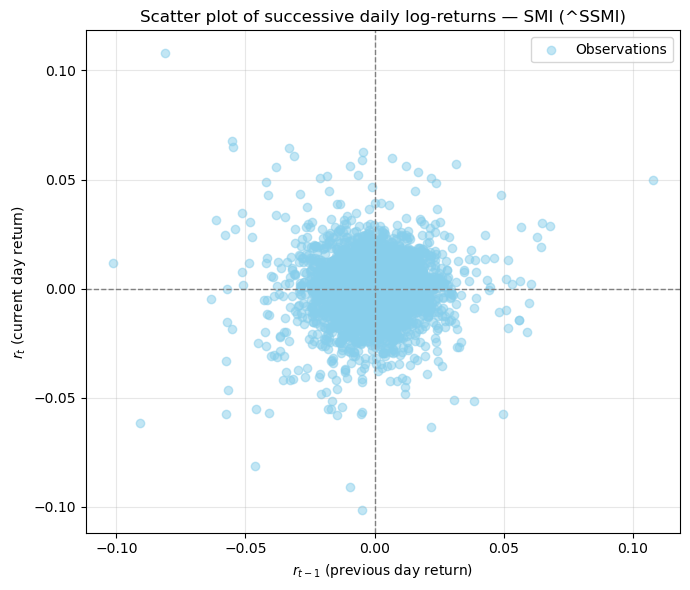

In [90]:
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression


# Download daily SMI price data (1999–2024)
smi = yf.download("^SSMI", start="1999-01-01", end="2024-12-31", progress=False)


# Select the price series ("Close" or "Adj Close")
price_col = "Close" if "Close" in smi.columns else "Adj Close"
price = smi[price_col].dropna()


# Compute log returns and build the lagged series
r = np.log(price / price.shift(1)).dropna()        # r_t: daily log return
r_lag1 = r.shift(1).dropna()                       # r_{t-1}: previous-day return
r_sync = r.loc[r_lag1.index]                       # match r_t and r_{t-1} on dates


# Linear regression: r_t = alpha + beta * r_{t-1}
X = r_lag1.values.reshape(-1, 1)                   # predictor (2D array)
y = r_sync.values                                  # response variable

reg = LinearRegression().fit(X, y)                 # fit OLS model

alpha = float(reg.intercept_)                      # estimated intercept
beta  = float(reg.coef_.ravel()[0])                # estimated slope
R2    = float(reg.score(X, y))                     # coefficient of determination


# Scatter plot of r_t versus r_{t-1}
plt.figure(figsize=(7, 6))
plt.scatter(r_lag1, r_sync, color='skyblue', alpha=0.5, label='Observations')

plt.axhline(0, color='gray', ls='--', lw=1)        # horizontal reference line
plt.axvline(0, color='gray', ls='--', lw=1)        # vertical reference line

plt.xlabel(r"$r_{t-1}$ (previous day return)")
plt.ylabel(r"$r_t$ (current day return)")
plt.title("Scatter plot of successive daily log-returns — SMI (^SSMI)")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


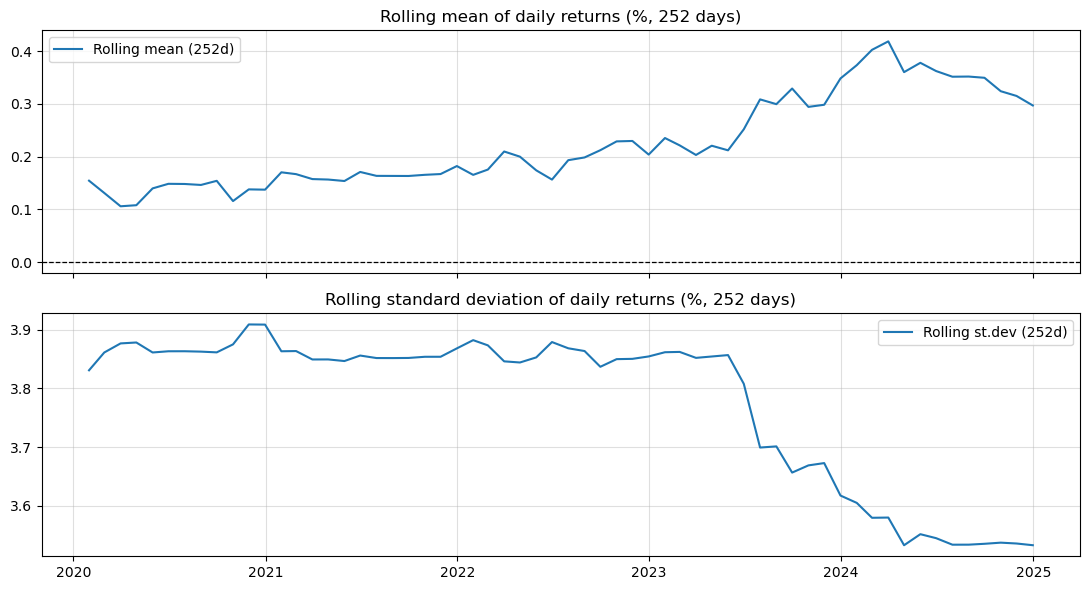

In [91]:
# Convert daily log returns to percentage units
ret_pct = 100 * ret_d.dropna()

# Rolling-window length (≈ 252 trading days ≈ 1 year)
win = 252

# Create two stacked subplots (mean and volatility)
fig, ax = plt.subplots(2, 1, figsize=(11, 6), sharex=True)

# Rolling mean of daily returns
ax[0].plot(ret_pct.rolling(win).mean(), label="Rolling mean (252d)")
ax[0].axhline(0, color="black", ls="--", lw=0.9)     # zero baseline
ax[0].legend()
ax[0].grid(True, alpha=0.4)
ax[0].set_title("Rolling mean of daily returns (%, 252 days)")


# Rolling standard deviation (volatility)
ax[1].plot(ret_pct.rolling(win).std(), label="Rolling st.dev (252d)")
ax[1].legend()
ax[1].grid(True, alpha=0.4)
ax[1].set_title("Rolling standard deviation of daily returns (%, 252 days)")

# Layout and render
plt.tight_layout()
plt.show()


/var/folders/sh/xy8x7lwj1kg1ffmgpdrrvdvh0000gn/T/ipykernel_30124/269200513.py:8: FutureWarning: YF.download() has changed argument auto_adjust default to True
  smi = yf.download("^SSMI", start="1999-01-01", end="2024-12-31", progress=False)


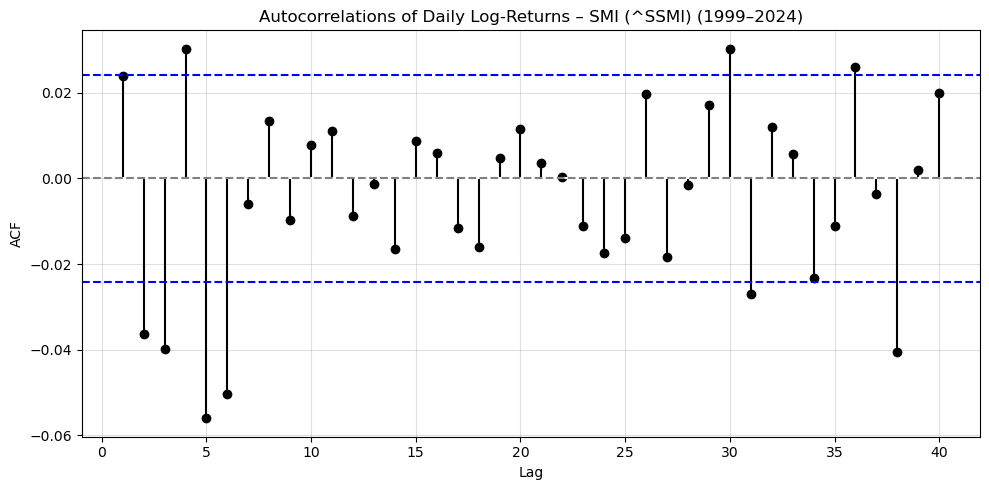

In [92]:
import yfinance as yf
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import acf


# Download SMI price data and compute daily log-returns
smi = yf.download("^SSMI", start="1999-01-01", end="2024-12-31", progress=False)
log_returns = np.log(smi['Close'] / smi['Close'].shift(1)).dropna()  # r_t


# Compute sample autocorrelations (course method)
lags = 40
acf_values = acf(log_returns, nlags=lags)                 # ACF for lags 0..40
bart_int = 1.96 / np.sqrt(len(log_returns))               # Bartlett bound ±1.96/√T


# Plot ACF with Bartlett confidence interval
plt.figure(figsize=(10, 5))

# Stem plot excluding lag 0
plt.stem(np.arange(1, lags + 1), acf_values[1:], 
         linefmt='k-', markerfmt='ko', basefmt='w-')

plt.axhline(y=0, color='gray', linestyle='--')            # zero reference
plt.axhline(y=bart_int, color='blue', linestyle='--')     # upper CI bound
plt.axhline(y=-bart_int, color='blue', linestyle='--')    # lower CI bound

plt.title("Autocorrelations of Daily Log-Returns – SMI (^SSMI) (1999–2024)")
plt.xlabel("Lag")
plt.ylabel("ACF")
plt.grid(True, alpha=0.4)
plt.tight_layout()
plt.show()


### Stylized fact 3 : Asymmetry

Skewness (SMI daily log-returns) = -0.2690


/var/folders/sh/xy8x7lwj1kg1ffmgpdrrvdvh0000gn/T/ipykernel_30124/1588876069.py:2: FutureWarning: YF.download() has changed argument auto_adjust default to True
  smi = yf.download("^SSMI", start="1999-01-01", end="2024-12-31", progress=False)


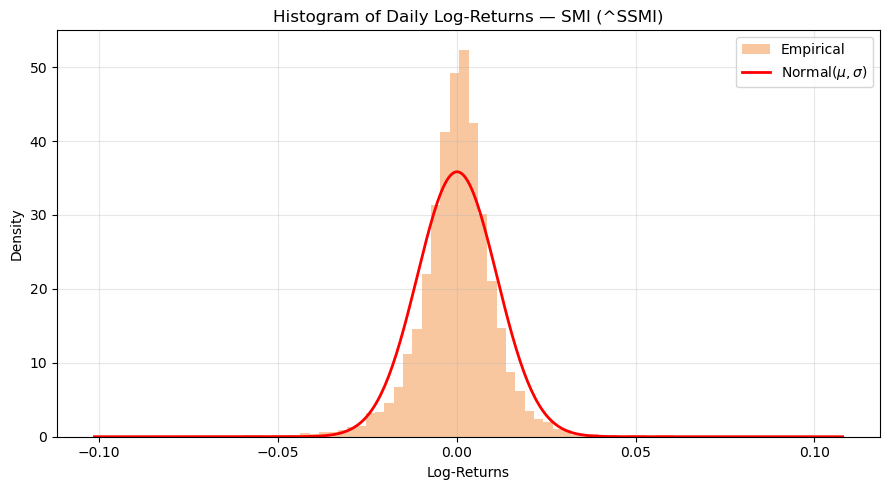

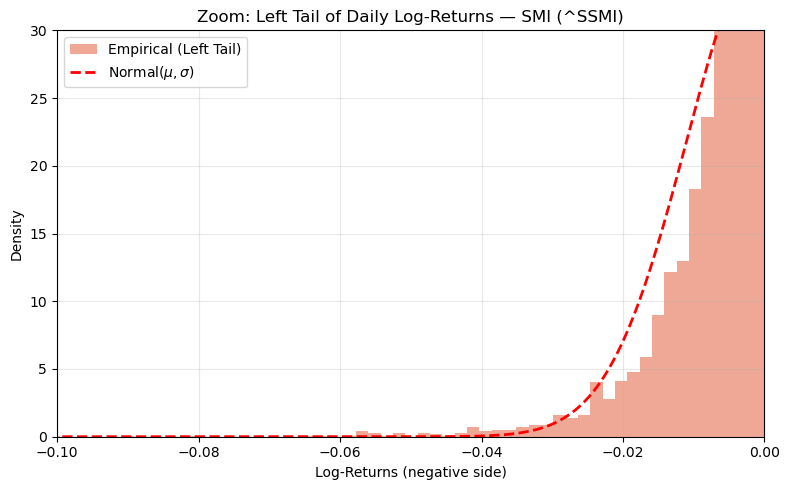

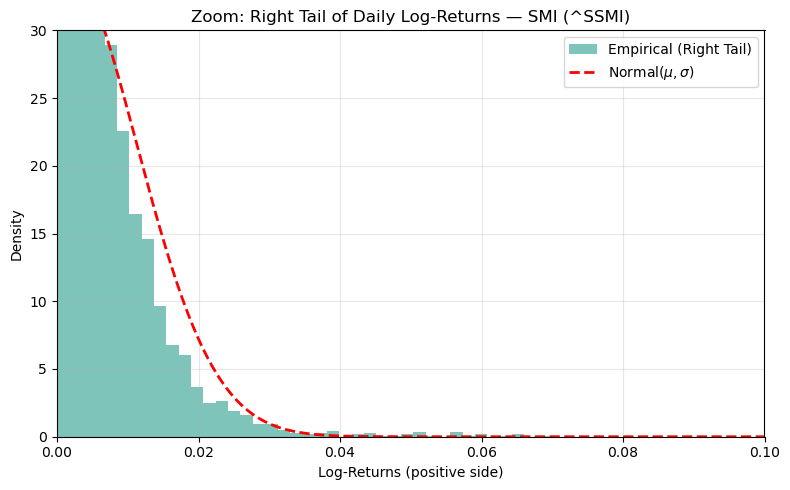

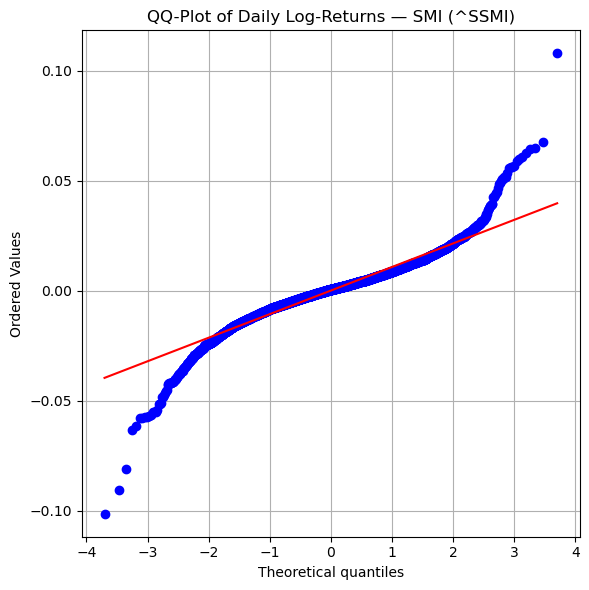

In [93]:
# Download SMI prices and compute daily log-returns
smi = yf.download("^SSMI", start="1999-01-01", end="2024-12-31", progress=False)
prices = smi["Close"].dropna()
log_returns = np.log(prices / prices.shift(1)).dropna()

# Convert returns to a NumPy array
r = np.asarray(log_returns).flatten()

# Compute sample skewness of daily log-returns
skewness_value = float(skew(r))
print(f"Skewness (SMI daily log-returns) = {skewness_value:.4f}")

# Histogram of daily log-returns with normal density overlay
plt.figure(figsize=(9, 5))
count, bins, _ = plt.hist(r, bins=80, density=True, alpha=0.6,
                          color="#f4a261", label="Empirical")

# Normal distribution with empirical mean and std
mu, sigma = r.mean(), r.std()
x = np.linspace(bins.min(), bins.max(), 400)
plt.plot(x, norm.pdf(x, mu, sigma), "r-", lw=2, label="Normal($\\mu,\\sigma$)")

plt.title("Histogram of Daily Log-Returns — SMI (^SSMI)")
plt.xlabel("Log-Returns")
plt.ylabel("Density")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("SF3_SMI_hist_returns.png", dpi=150, bbox_inches="tight")
plt.show()

# Zoom on the left tail (negative returns)
plt.figure(figsize=(8, 5))
plt.hist(r, bins=120, density=True, alpha=0.6,
         color="#e76f51", label="Empirical (Left Tail)")
plt.plot(x, norm.pdf(x, mu, sigma), "r--", lw=2,
         label="Normal($\\mu,\\sigma$)")

plt.xlim(-0.10, 0.00)     # focus on large negative returns
plt.ylim(0, 30)
plt.title("Zoom: Left Tail of Daily Log-Returns — SMI (^SSMI)")
plt.xlabel("Log-Returns (negative side)")
plt.ylabel("Density")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("SF3_SMI_left_tail_zoom.png", dpi=150, bbox_inches="tight")
plt.show()

# Zoom on the right tail (positive returns)
plt.figure(figsize=(8, 5))
plt.hist(r, bins=120, density=True, alpha=0.6,
         color="#2a9d8f", label="Empirical (Right Tail)")
plt.plot(x, norm.pdf(x, mu, sigma), "r--", lw=2,
         label="Normal($\\mu,\\sigma$)")

plt.xlim(0.00, 0.10)      # focus on large positive returns
plt.ylim(0, 30)
plt.title("Zoom: Right Tail of Daily Log-Returns — SMI (^SSMI)")
plt.xlabel("Log-Returns (positive side)")
plt.ylabel("Density")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("SF3_SMI_right_tail_zoom.png", dpi=150, bbox_inches="tight")
plt.show()

# QQ-Plot against the normal distribution
plt.figure(figsize=(6, 6))
probplot(r, dist="norm", plot=plt)
plt.title("QQ-Plot of Daily Log-Returns — SMI (^SSMI)")
plt.tight_layout()
plt.show()


 ### Stylized fact 4 : Heavy tails

/var/folders/sh/xy8x7lwj1kg1ffmgpdrrvdvh0000gn/T/ipykernel_30124/3294871840.py:7: FutureWarning: YF.download() has changed argument auto_adjust default to True
  smi = yf.download("^SSMI", start="1999-01-01", end="2024-12-31", progress=False)
/var/folders/sh/xy8x7lwj1kg1ffmgpdrrvdvh0000gn/T/ipykernel_30124/3294871840.py:14: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  ret_m = np.log(prices.resample("M").last() /
/var/folders/sh/xy8x7lwj1kg1ffmgpdrrvdvh0000gn/T/ipykernel_30124/3294871840.py:15: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  prices.resample("M").last().shift(1)).dropna()
/var/folders/sh/xy8x7lwj1kg1ffmgpdrrvdvh0000gn/T/ipykernel_30124/3294871840.py:18: FutureWarning: 'Y' is deprecated and will be removed in a future version, please use 'YE' instead.
  ret_y = np.log(prices.resample("Y").last() /
/var/folders/sh/xy8x7lwj1kg1ffmgpdrrvdvh0000gn/T/ipykernel_30124/329

---- Excess Kurtosis (Leptokurtosis indicator) ----
Daily   : 7.589
Monthly : 0.723
Annual  : 0.588


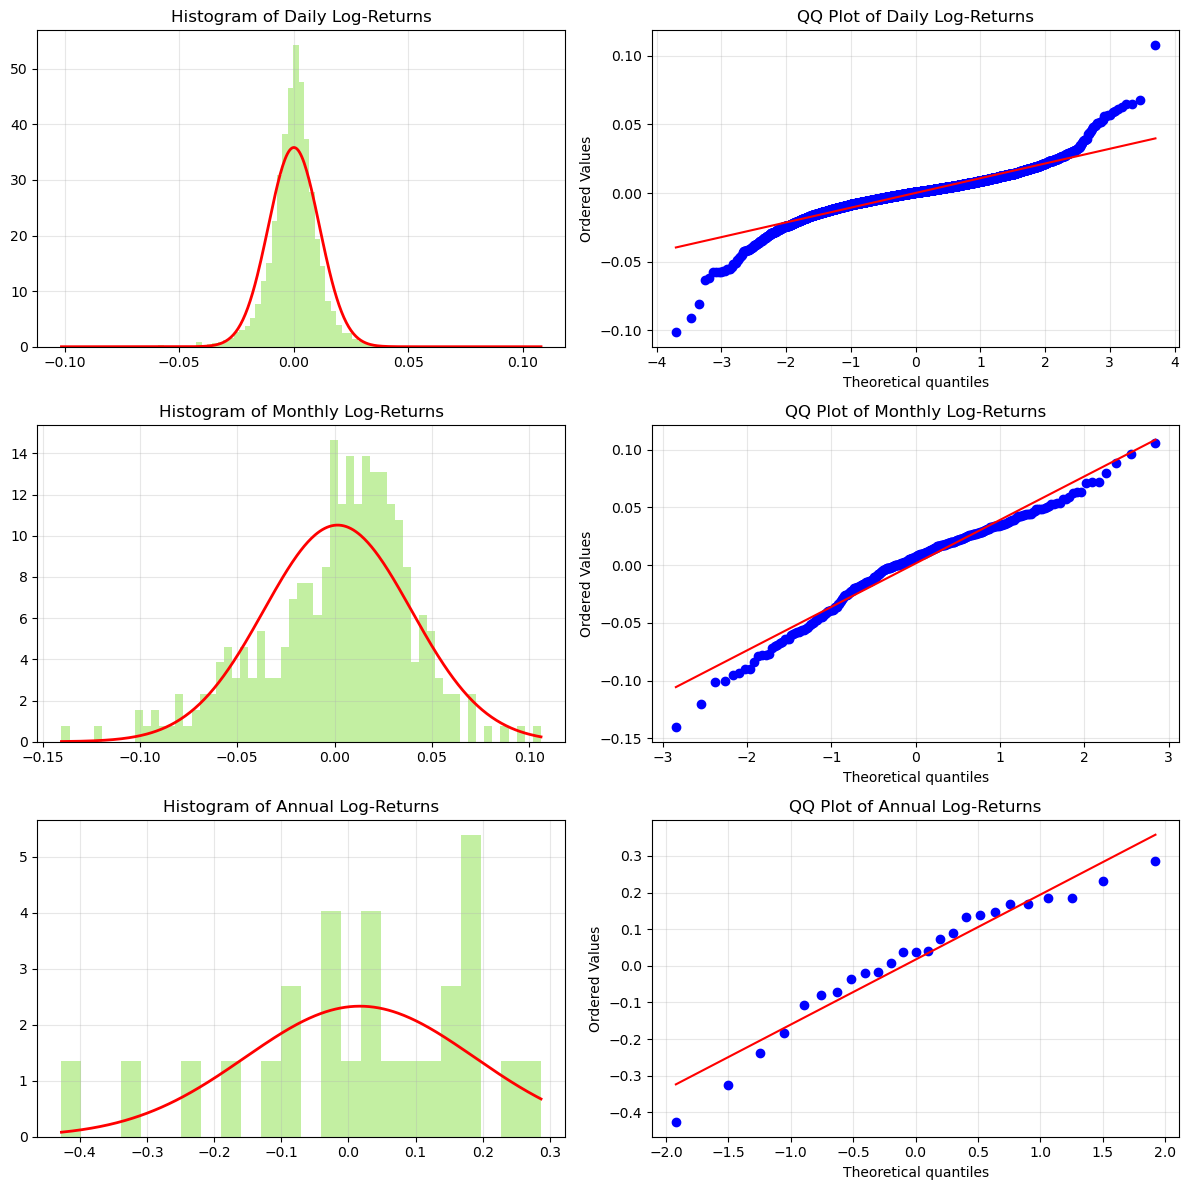

In [94]:
import yfinance as yf
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import kurtosis, norm, probplot

# Download SMI prices and compute log-returns at 3 frequencies
smi = yf.download("^SSMI", start="1999-01-01", end="2024-12-31", progress=False)
prices = smi["Close"].dropna()

# Daily log-returns
ret_d = np.log(prices / prices.shift(1)).dropna()

# Monthly log-returns (last trading day of each month)
ret_m = np.log(prices.resample("M").last() /
               prices.resample("M").last().shift(1)).dropna()

# Annual log-returns (last trading day of each year)
ret_y = np.log(prices.resample("Y").last() /
               prices.resample("Y").last().shift(1)).dropna()

# Convert to 1D NumPy arrays
rd = np.asarray(ret_d).flatten()   # daily
rm = np.asarray(ret_m).flatten()   # monthly
ry = np.asarray(ret_y).flatten()   # annual

# Excess kurtosis function (leptokurtosis indicator)
def excess_kurt(x):
    return float(kurtosis(x, fisher=True, bias=False))

exk_d = excess_kurt(rd)
exk_m = excess_kurt(rm)
exk_y = excess_kurt(ry)

print("---- Excess Kurtosis (Leptokurtosis indicator) ----")
print(f"Daily   : {exk_d:.3f}")
print(f"Monthly : {exk_m:.3f}")
print(f"Annual  : {exk_y:.3f}")

# Histograms + normal fits and QQ-plots (daily, monthly, annual)
fig, ax = plt.subplots(3, 2, figsize=(12, 12))

# Daily
mu, sd = rd.mean(), rd.std()
bins = np.linspace(rd.min(), rd.max(), 90)
ax[0, 0].hist(rd, bins=bins, density=True, alpha=0.6, color="#9be564")
x = np.linspace(bins.min(), bins.max(), 400)
ax[0, 0].plot(x, norm.pdf(x, mu, sd), "r-", lw=2)    # normal overlay
ax[0, 0].set_title("Histogram of Daily Log-Returns")
ax[0, 0].grid(True, alpha=0.3)

probplot(rd, dist="norm", plot=ax[0, 1])             # QQ-plot vs normal
ax[0, 1].set_title("QQ Plot of Daily Log-Returns")
ax[0, 1].grid(True, alpha=0.3)

# Monthly
mu, sd = rm.mean(), rm.std()
bins = np.linspace(rm.min(), rm.max(), 60)
ax[1, 0].hist(rm, bins=bins, density=True, alpha=0.6, color="#9be564")
x = np.linspace(bins.min(), bins.max(), 400)
ax[1, 0].plot(x, norm.pdf(x, mu, sd), "r-", lw=2)
ax[1, 0].set_title("Histogram of Monthly Log-Returns")
ax[1, 0].grid(True, alpha=0.3)

probplot(rm, dist="norm", plot=ax[1, 1])
ax[1, 1].set_title("QQ Plot of Monthly Log-Returns")
ax[1, 1].grid(True, alpha=0.3)

# Annual
mu, sd = ry.mean(), ry.std()
bins = np.linspace(ry.min(), ry.max(), 25)
ax[2, 0].hist(ry, bins=bins, density=True, alpha=0.6, color="#9be564")
x = np.linspace(bins.min(), bins.max(), 400)
ax[2, 0].plot(x, norm.pdf(x, mu, sd), "r-", lw=2)
ax[2, 0].set_title("Histogram of Annual Log-Returns")
ax[2, 0].grid(True, alpha=0.3)

probplot(ry, dist="norm", plot=ax[2, 1])
ax[2, 1].set_title("QQ Plot of Annual Log-Returns")
ax[2, 1].grid(True, alpha=0.3)

# Global layout and export
plt.tight_layout()
plt.show()


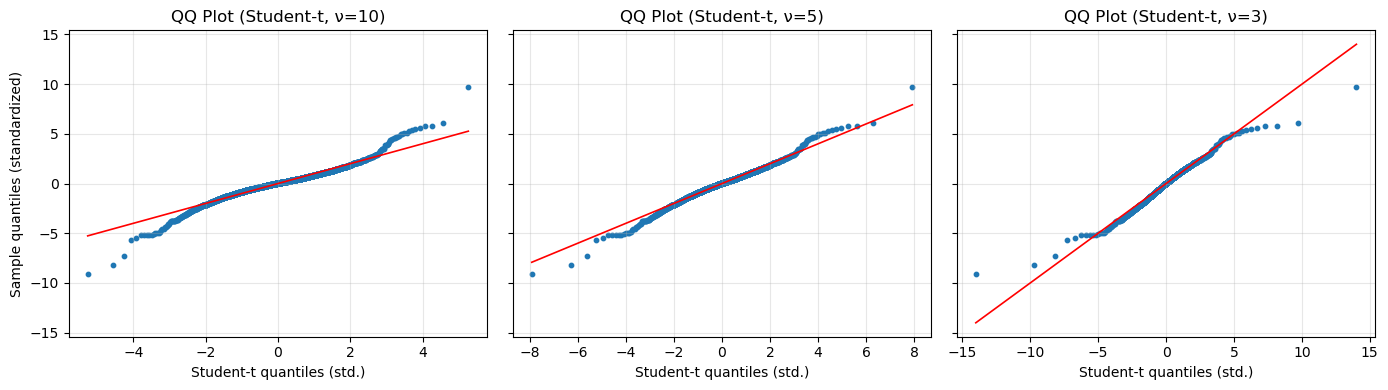

In [95]:
from scipy.stats import t as student_t

# Standardize daily log-returns (mean 0, variance 1)
z = (np.asarray(ret_d).flatten() - np.asarray(ret_d).mean()) / np.asarray(ret_d).std()
z = np.sort(z)                   # sorted sample quantiles
n = z.size
p = (np.arange(1, n+1) - 0.5) / n   # plotting positions in (0,1)

# Student-t theoretical quantiles with unit variance
def standardized_t_quantiles(p, nu):
    # Variance-normalizing scale factor: sqrt((ν−2)/ν), valid for ν > 2
    scale = np.sqrt((nu - 2.0) / nu)
    return student_t.ppf(p, df=nu, loc=0.0, scale=scale)

# Degrees of freedom to compare (as in the slides)
dfs = [10, 5, 3]

# QQ-plots: standardized Student-t vs standardized data
fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)

for ax, nu in zip(axes, dfs):
    q_t = standardized_t_quantiles(p, nu)    # theoretical quantiles
    ax.scatter(q_t, z, s=10, color="tab:blue")

    # 45-degree line (perfect fit under the reference distribution)
    qmin, qmax = np.nanmin(q_t), np.nanmax(q_t)
    qline = np.linspace(qmin, qmax, 200)
    ax.plot(qline, qline, "r-", lw=1.2)

    ax.set_title(f"QQ Plot (Student-t, ν={nu})")
    ax.set_xlabel("Student-t quantiles (std.)")
    ax.grid(True, alpha=0.3)

# Common y-axis label for all panels
axes[0].set_ylabel("Sample quantiles (standardized)")

plt.tight_layout()
plt.savefig("SF4_SMI_QQ_studentt_v10_v5_v3.png", dpi=150, bbox_inches="tight")
plt.show()


### Stylized fact 5 :  Aggregational Gaussianity

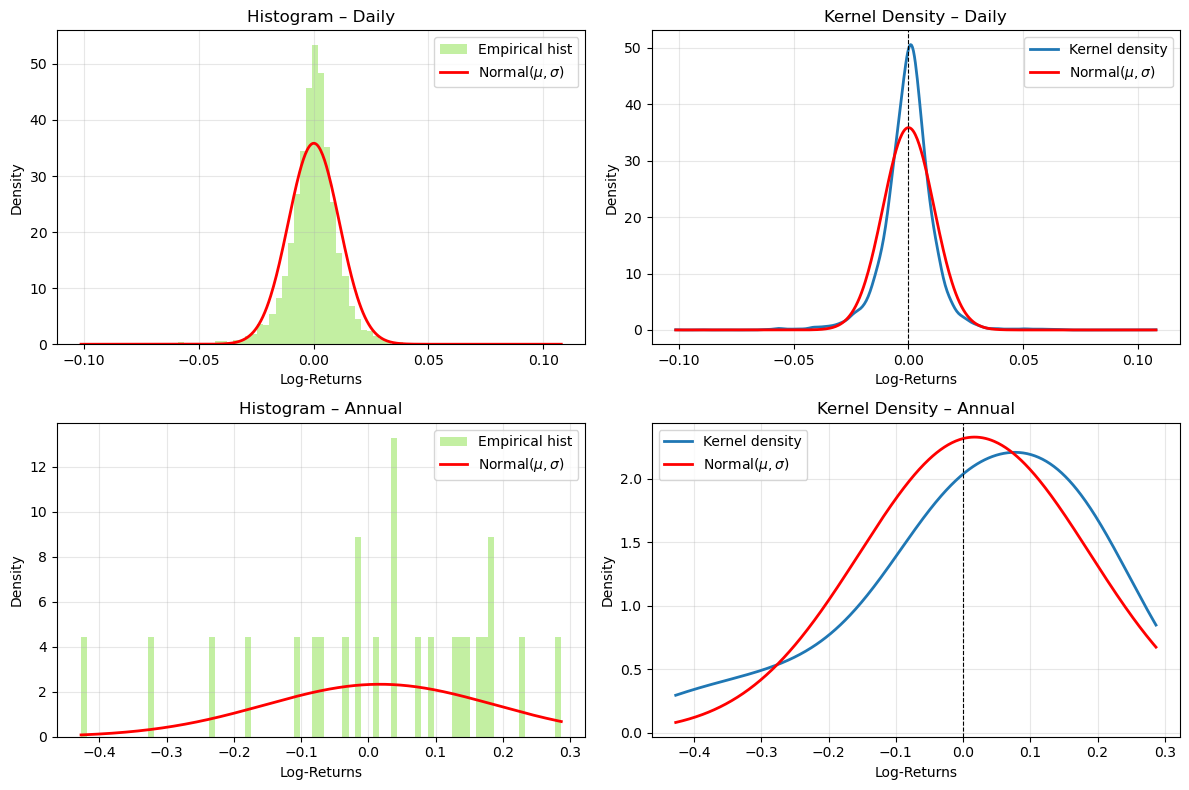

In [96]:
from scipy.stats import norm, probplot, skew, kurtosis, gaussian_kde
from statsmodels.stats.diagnostic import lilliefors

# Function: histogram + normal PDF + KDE, for a given return series
def plot_hist_kde_vs_normal(x, title, ax_hist, ax_kde):
    x = np.asarray(x).flatten()                   # ensure 1D vector
    mu, sigma = x.mean(), x.std()                 # empirical mean and standard deviation

    # Histogram with Normal(μ, σ) overlay
    bins = np.linspace(x.min(), x.max(), 80)
    ax_hist.hist(x, bins=bins, density=True, alpha=0.6,
                 color="#9be564", edgecolor='none', label="Empirical hist")

    xs = np.linspace(bins.min(), bins.max(), 500)
    ax_hist.plot(xs, norm.pdf(xs, mu, sigma), "r-", lw=2,
                 label="Normal($\\mu,\\sigma$)")

    ax_hist.set_title(f"Histogram – {title}")
    ax_hist.set_xlabel("Log-Returns")
    ax_hist.set_ylabel("Density")
    ax_hist.legend()
    ax_hist.grid(True, alpha=0.3)

    # Kernel density estimate (KDE) vs Normal(μ, σ)
    kde = gaussian_kde(x)
    ax_kde.plot(xs, kde(xs), color="tab:blue", lw=2, label="Kernel density")
    ax_kde.plot(xs, norm.pdf(xs, mu, sigma), "r-", lw=2,
                label="Normal($\\mu,\\sigma$)")

    ax_kde.axvline(0, color="k", ls="--", lw=0.8) # zero reference line
    ax_kde.set_title(f"Kernel Density – {title}")
    ax_kde.set_xlabel("Log-Returns")
    ax_kde.set_ylabel("Density")
    ax_kde.legend()
    ax_kde.grid(True, alpha=0.3)

# Plot histograms + KDE for daily and annual log-returns
fig, ax = plt.subplots(2, 2, figsize=(12, 8))

plot_hist_kde_vs_normal(ret_d, "Daily",  ax[0,0], ax[0,1])
plot_hist_kde_vs_normal(ret_y, "Annual", ax[1,0], ax[1,1])

plt.tight_layout()
plt.show()


/var/folders/sh/xy8x7lwj1kg1ffmgpdrrvdvh0000gn/T/ipykernel_30124/1040559035.py:4: RuntimeWarning: Mean of empty slice.
  z = (np.asarray(x).flatten() - np.asarray(x).mean()) / np.asarray(x).std()
/opt/anaconda3/lib/python3.13/site-packages/numpy/_core/_methods.py:147: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
/opt/anaconda3/lib/python3.13/site-packages/numpy/_core/_methods.py:227: RuntimeWarning: Degrees of freedom <= 0 for slice
  ret = _var(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/opt/anaconda3/lib/python3.13/site-packages/numpy/_core/_methods.py:184: RuntimeWarning: invalid value encountered in divide
  arrmean = um.true_divide(arrmean, div, out=arrmean,
/opt/anaconda3/lib/python3.13/site-packages/numpy/_core/_methods.py:219: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


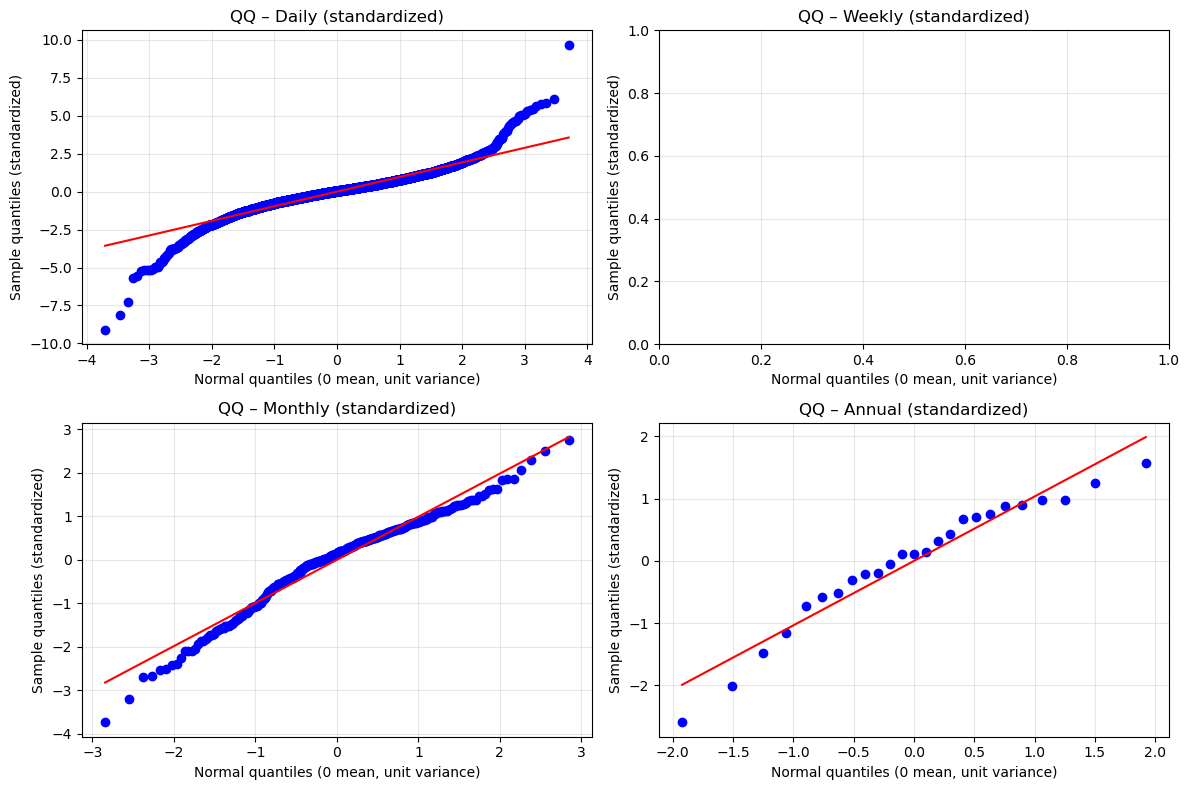

In [97]:
# Function: QQ-plot of standardized returns vs Normal(0,1)
def qq_std_vs_normal(x, ax, title):
    # Standardize the data: (x − mean) / std
    z = (np.asarray(x).flatten() - np.asarray(x).mean()) / np.asarray(x).std()

    # QQ-plot comparing standardized sample quantiles vs N(0,1)
    probplot(z, dist="norm", plot=ax)

    ax.set_title(title)
    ax.grid(True, alpha=0.3)
    ax.set_xlabel("Normal quantiles (0 mean, unit variance)")
    ax.set_ylabel("Sample quantiles (standardized)")

# QQ-plots for daily, weekly, monthly, annual log-returns
fig, ax = plt.subplots(2, 2, figsize=(12, 8))

qq_std_vs_normal(ret_d, ax[0,0], "QQ – Daily (standardized)")
qq_std_vs_normal(ret_w, ax[0,1], "QQ – Weekly (standardized)")
qq_std_vs_normal(ret_m, ax[1,0], "QQ – Monthly (standardized)")
qq_std_vs_normal(ret_y, ax[1,1], "QQ – Annual (standardized)")

plt.tight_layout()
plt.savefig("SF5_SMI_QQ_std_D_W_M_Y.png", dpi=150, bbox_inches="tight")
plt.show()


In [99]:
import numpy as np
import pandas as pd
from scipy.stats import skew, kurtosis
from statsmodels.stats.diagnostic import lilliefors

# Utility: safely convert various inputs to a 1D Series
def to_1d(x):
    # Accepts Series, 1-column DataFrame, NumPy array, or list
    if isinstance(x, pd.DataFrame):
        x = x.iloc[:, 0]
    x = np.asarray(x).squeeze()          # remove extra dimension (n, 1) → (n,)
    return pd.Series(x).dropna()         # return clean 1D Series without NaN

# Rebuild return series at 4 frequencies if not already defined
try:
    ret_d, ret_w, ret_m, ret_y          # check if they exist in the workspace
except NameError:
    prices_w = prices.resample("W-FRI").last()
    prices_m = prices.resample("M").last()
    prices_y = prices.resample("Y").last()

    ret_d = np.log(prices / prices.shift(1)).dropna()
    ret_w = np.log(prices_w / prices_w.shift(1)).dropna()
    ret_m = np.log(prices_m / prices_m.shift(1)).dropna()
    ret_y = np.log(prices_y / prices_y.shift(1)).dropna()

# Compute skewness, excess kurtosis, and Lilliefors test
def moments_and_lillie(x):
    s = to_1d(x)                         # ensure 1D cleaned Series
    sk  = float(skew(s))                 # sample skewness
    exk = float(kurtosis(s, fisher=True))# excess kurtosis (0 for normal)
    stat, pval = lilliefors(s.values)    # Lilliefors normality test on 1D array
    return sk, exk, stat, pval, int(len(s))

# Build summary table for all frequencies
rows = []
for name, s in [("Daily", ret_d),
                ("Weekly", ret_w),
                ("Monthly", ret_m),
                ("Annual", ret_y)]:
    rows.append((name, *moments_and_lillie(s)))

sf5_tbl = pd.DataFrame(
    rows,
    columns=["Freq", "Skewness", "ExcessKurtosis", "Lillie.stat", "Lillie.pval", "N"]
)

# Nicely formatted table output
display(
    sf5_tbl.style.format({
        "Skewness": "{:.3f}",
        "ExcessKurtosis": "{:.3f}",
        "Lillie.stat": "{:.3f}",
        "Lillie.pval": "{:.4f}",
    })
)


/var/folders/sh/xy8x7lwj1kg1ffmgpdrrvdvh0000gn/T/ipykernel_30124/286253477.py:30: SmallSampleWarning: One or more sample arguments is too small; all returned values will be NaN. See documentation for sample size requirements.
  sk  = float(skew(s))                 # sample skewness
/var/folders/sh/xy8x7lwj1kg1ffmgpdrrvdvh0000gn/T/ipykernel_30124/286253477.py:31: SmallSampleWarning: One or more sample arguments is too small; all returned values will be NaN. See documentation for sample size requirements.
  exk = float(kurtosis(s, fisher=True))# excess kurtosis (0 for normal)
/opt/anaconda3/lib/python3.13/site-packages/statsmodels/stats/_lilliefors.py:279: RuntimeWarning: Mean of empty slice.
  z = (x - x.mean()) / x.std(ddof=1)
/opt/anaconda3/lib/python3.13/site-packages/numpy/_core/_methods.py:147: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
/opt/anaconda3/lib/python3.13/site-packages/numpy/_core/_methods.py:227: RuntimeWarning: Degre

ValueError: Test for distribution norm requires at least 4 observations

### Stylized fact 6 : Autocorrelation

In [ ]:
import yfinance as yf
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import acf

# Download SMI (^SSMI) closing prices
px = yf.download("^SSMI", start="1999-01-01", end="2024-12-31",
                 progress=False)["Close"].dropna()

# Compute log-returns at daily, weekly, and monthly frequency
r_d = np.log(px).diff().dropna().squeeze()                          # Daily log-returns
r_w = np.log(px.resample("W-FRI").last()).diff().dropna().squeeze() # Weekly log-returns (Friday close)
r_m = np.log(px.resample("M").last()).diff().dropna().squeeze()     # Monthly log-returns


# Helper: ACF and Bartlett confidence band
def acf_and_bartlett(r, lags=40):
    vals = acf(np.asarray(r), nlags=lags, fft=True)[1:]  # drop lag 0
    band = 1.96 / np.sqrt(len(r))                        # Bartlett band ±1.96/√T
    x = np.arange(1, lags + 1)
    return x, vals, band

# Compute ACFs for each frequency
lags = 40
x_d, acf_d, b_d = acf_and_bartlett(r_d, lags)
x_w, acf_w, b_w = acf_and_bartlett(r_w, lags)
x_m, acf_m, b_m = acf_and_bartlett(r_m, lags)

# Common plotting function for correlograms (first definition)
def draw_acf(ax, x, acf_vals, band, title):
    ax.stem(x, acf_vals, linefmt='k-', markerfmt='ko', basefmt='w-')
    ax.axhline(0, color='gray', linestyle='--')

    # Bartlett bands (±1.96/√T)
    ax.axhline(band, color='tab:blue', linestyle='--', linewidth=2,
               label=r'$\pm\,1.96/\sqrt{T}$')
    ax.axhline(-band, color='tab:blue', linestyle='--', linewidth=2)

    # Shaded confidence band
    ax.axhspan(-band, band, color='tab:blue', alpha=0.12)

    ax.set_xlim(1, x[-1])
    ax.set_ylim(-0.15, 0.30)
    ax.set_title(title)
    ax.set_xlabel("Lag")
    ax.set_ylabel("ACF")
    ax.grid(True, alpha=0.3)
    ax.legend(loc="upper right", frameon=False)

# Overloaded version with optional zoom argument
def draw_acf(ax, x, acf_vals, band, title, zoom=False):
    ax.stem(x, acf_vals, linefmt='k-', markerfmt='ko', basefmt='w-')
    ax.axhline(0, color='gray', linestyle='--')

    # Bartlett bands (±1.96/√T)
    ax.axhline(band, color='tab:blue', linestyle='--', linewidth=2,
               label=r'$\pm\,1.96/\sqrt{T}$')
    ax.axhline(-band, color='tab:blue', linestyle='--', linewidth=2)
    ax.axhspan(-band, band, color='tab:blue', alpha=0.12)

    ax.set_xlim(1, x[-1])
    # Global view vs zoomed view on small autocorrelations
    if zoom:
        ax.set_ylim(-0.1, 0.1)   # zoomed scale
    else:
        ax.set_ylim(-0.15, 0.30)

    ax.set_title(title)
    ax.set_xlabel("Lag")
    ax.set_ylabel("ACF")
    ax.grid(True, alpha=0.3)
    ax.legend(loc="upper right", frameon=False)


# Plot correlograms (full scale)
fig, axs = plt.subplots(1, 3, figsize=(18, 6))
draw_acf(axs[0], x_d, acf_d, b_d, "ACF – Daily Log-Returns (SMI ^SSMI)")
draw_acf(axs[1], x_w, acf_w, b_w, "ACF – Weekly (Fri) Log-Returns (SMI ^SSMI)")
draw_acf(axs[2], x_m, acf_m, b_m, "ACF – Monthly Log-Returns (SMI ^SSMI)")

# Plot correlograms (zoomed around zero)
fig, axs = plt.subplots(1, 3, figsize=(18, 6))
draw_acf(axs[0], x_d, acf_d, b_d, "ACF – Daily Log-Returns (SMI ^SSMI)", zoom=True)
draw_acf(axs[1], x_w, acf_w, b_w, "ACF – Weekly (Fri) Log-Returns (SMI ^SSMI)", zoom=True)
draw_acf(axs[2], x_m, acf_m, b_m, "ACF – Monthly Log-Returns (SMI ^SSMI)", zoom=True)

plt.tight_layout()
plt.show()


### Stylized fact 7 : Volatility clustering

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import acf

# Helper: ACF with Bartlett confidence bands
def acf_with_bartlett(ax, series, lags, title, y_top=0.30):
    """ACF plot (lags 1..lags) with Bartlett ±1.96/sqrt(T) bands."""
    s = np.asarray(series.dropna()).astype(float)
    T = len(s)

    # Sample autocorrelations (discard lag 0)
    rho = acf(s, nlags=lags, fft=True)[1:]
    x = np.arange(1, lags + 1)

    # ACF stem plot
    ax.stem(x, rho, linefmt='k-', markerfmt='ko', basefmt='w-')

    # Zero horizontal line
    ax.axhline(0.0, color='gray', linestyle='--', linewidth=1)

    # Bartlett bands: ±1.96 / sqrt(T)
    band = 1.96 / np.sqrt(T)
    ax.plot(x,  band * np.ones_like(x), ls='--', color='tab:blue')
    ax.plot(x, -band * np.ones_like(x), ls='--', color='tab:blue')

    ax.set_ylim(-0.10, y_top)
    ax.set_xlabel('Lag')
    ax.set_ylabel('ACF')
    ax.set_title(title)
    ax.grid(True, alpha=0.3)


# ACF of squared returns (r_t²)
lags = 40
rd2 = ret_d**2
rw2 = ret_w**2
rm2 = ret_m**2

fig, ax = plt.subplots(1, 3, figsize=(18, 6))
acf_with_bartlett(ax[0], rd2, lags,
                  "ACF — Daily Squared Log-Returns (SMI ^SSMI)")
acf_with_bartlett(ax[1], rw2, lags,
                  "ACF — Weekly Squared Log-Returns (SMI ^SSMI)")
acf_with_bartlett(ax[2], rm2, lags,
                  "ACF — Monthly Squared Log-Returns (SMI ^SSMI)")
plt.tight_layout()
plt.savefig("SF7_SMI_acf_squared_returns_dwm.png", dpi=150, bbox_inches="tight")
plt.show()

# ACF of absolute returns (|r_t|)
fig, ax = plt.subplots(1, 3, figsize=(18, 6))
acf_with_bartlett(ax[0], ret_d.abs(), lags,
                  "ACF — Daily Absolute Log-Returns (SMI ^SSMI)")
acf_with_bartlett(ax[1], ret_w.abs(), lags,
                  "ACF — Weekly Absolute Log-Returns (SMI ^SSMI)")
acf_with_bartlett(ax[2], ret_m.abs(), lags,
                  "ACF — Monthly Absolute Log-Returns (SMI ^SSMI)")
plt.tight_layout()
plt.savefig("SF7_SMI_acf_abs_returns_dwm.png", dpi=150, bbox_inches="tight")
plt.show()

# Rolling 1-year standard deviation of daily returns
r_d = ret_d.dropna()
roll_sd_252 = r_d.rolling(252).std() * 100.0   # 252-day rolling volatility in %

plt.figure(figsize=(12, 5))
plt.plot(roll_sd_252.index, roll_sd_252,
         color='tab:blue', linewidth=1.8,
         label="Rolling st.dev (252 days)")

plt.title("Rolling 1-Year Standard Deviation of Daily Log-Returns — SMI (^SSMI)")
plt.ylabel("Standard deviation (%)")
plt.xlabel("Date")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


### Stylized fact 8 : Leverage effect

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import yfinance as yf
import scipy.signal as ss

# Cross-correlation function corr(x_{t-j}, y_t) for j = -lag_max..+lag_max
def ccf(x: np.ndarray, y: np.ndarray, lag_max: int = 10) -> np.ndarray:
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)

    # Full cross-correlation of centered series, normalized by T * σ_x * σ_y
    res = ss.correlate(y - y.mean(),
                       x - x.mean(),
                       method='direct') / (x.std() * y.std() * len(y))

    # Extract the window corresponding to lags -lag_max..+lag_max
    L = (len(res) - 1) // 2
    lo, hi = L - lag_max, L + lag_max + 1
    return res[lo:hi]

# Download SMI (^SSMI) data and compute daily log-returns
smi = yf.download("^SSMI",
                  start="1999-01-04",
                  end="2024-12-30",
                  progress=False)["Close"].dropna()

# Daily log-returns r_t
r = np.log(smi).diff().dropna()
T = len(r)

# Cross-correlation corr(r_{t+j}, r_t^2)
lag_max = 10
lags = np.arange(-lag_max, lag_max + 1)

# ccf(r_{t-j}, r_t^2), evaluated for j = -lag_max..+lag_max
xc = ccf(r.values, (r.values**2), lag_max=lag_max)

# Bartlett confidence bands ±1.96 / sqrt(T)
bart = 1.96 / np.sqrt(T)
upper = np.full_like(lags, +bart, dtype=float)
lower = np.full_like(lags, -bart, dtype=float)

# Plot cross-correlation with Bartlett bounds
plt.figure(figsize=(9, 5.5))

markerline, stemlines, baseline = plt.stem(lags, xc)
plt.setp(stemlines, color="k")
plt.setp(markerline, markerfacecolor="k")

plt.axhline(0, color="red", lw=1)          # zero reference line
plt.plot(lags, upper, "g--", lw=1.5)       # upper Bartlett band
plt.plot(lags, lower, "g--", lw=1.5)       # lower Bartlett band

plt.xlabel("Lag (days)")
plt.ylabel("Cross-Correlation")
plt.title(r"Cross-Correlation between daily $r_{t-j}$ and $r_t^2$ — SMI (^SSMI)")

# Optional: adjust vertical scale to highlight the peak around j = 0
y_pad = 0.05
plt.ylim(xc.min() - y_pad, max(xc.max(), bart) + y_pad)

plt.grid(True, alpha=0.35)
plt.tight_layout()
plt.show()

print(f"T = {T} obs — Bartlett bands ±{bart:.3f}")


# Question 2

In [102]:
# === CAPM (SMI + Developed Markets factors) — FIX index factors with spaces ===
import pandas as pd
import numpy as np
import yfinance as yf
import statsmodels.api as sm
from statsmodels.iolib.summary2 import summary_col
import re

# Parameters
TICKER = "^SSMI"
START = "1999-01-01"
END   = "2024-12-31"

# Monthly prices from Yahoo Finance
data_yf = yf.download(TICKER, start=START, end=END, interval="1mo")

# Use monthly closing prices and clean the index
prices = data_yf["Close"].dropna().sort_index()

# Convert index to month-end timestamps (Period → Timestamp at month end)
prices.index = pd.to_datetime(prices.index).to_period("M").to_timestamp("M")

# Remove potential duplicate month-end entries
prices = prices[~prices.index.duplicated(keep="last")]

# Compute monthly log-returns
Ri = np.log(prices).diff().dropna()
Ri.name = "Ri"

# Developed Markets factors (clean '199007 ' index etc.)
ff_raw = pd.read_csv("Developed_3_Factors.csv", skiprows=6)

# Strip whitespace from column names
ff_raw.columns = [c.strip() for c in ff_raw.columns]

# Ensure first column is named 'Date'
if ff_raw.columns[0].lower() != "date":
    ff_raw = ff_raw.rename(columns={ff_raw.columns[0]: "Date"})

# Clean Date column: trim spaces and keep only valid YYYYMM rows
ff_raw["Date"] = ff_raw["Date"].astype(str).str.strip()
ff_raw = ff_raw[ff_raw["Date"].str.match(r"^\d{6}$", na=False)]

# Convert YYYYMM to month-end timestamps
ff_raw["Date"] = (
    pd.to_datetime(ff_raw["Date"], format="%Y%m")
      .dt.to_period("M")
      .dt.to_timestamp("M")
)

ff = ff_raw.set_index("Date")

# Keep only the factor columns needed
ff.columns = [c.strip() for c in ff.columns]
needed = ["Mkt-RF", "SMB", "HML", "RF"]

ff = (
    ff[needed]
    .apply(pd.to_numeric, errors="coerce")  # ensure numeric
    .dropna()
)

# Remove duplicated dates if any
ff = ff[~ff.index.duplicated(keep="last")]

# Align factor data and SMI returns
common_idx = Ri.index.intersection(ff.index)

# Basic sanity check if there is no overlap in dates
if len(common_idx) == 0:
    print("Example Ri index:", Ri.index[:5])
    print("Example FF index:", ff.index[:5])
    raise ValueError("No common dates — check START/END and the factors file.")

# Merge into a single DataFrame on the common index
data = pd.concat([Ri.loc[common_idx], ff.loc[common_idx]], axis=1).dropna()
data.columns = ["Ri", "Mkt-RF", "SMB", "HML", "RF"]

# Excess return on the SMI in percentage points
data["Ri_minus_RF"] = data["Ri"] * 100 - data["RF"]

# CAPM regression: Ri - RF = alpha + beta * (Mkt - RF)
Y = data["Ri_minus_RF"]           # dependent variable
X = sm.add_constant(data["Mkt-RF"])  # constant + market excess return

model_capm = sm.OLS(Y, X).fit()

# Clean regression summary table
results_table = summary_col(
    [model_capm],
    stars=True,
    float_format='%0.4f',
    model_names=['CAPM (SMI)'],
    info_dict={'N': lambda x: f"{int(x.nobs)}"}
)

print(results_table)


/var/folders/sh/xy8x7lwj1kg1ffmgpdrrvdvh0000gn/T/ipykernel_30124/3774180418.py:15: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data_yf = yf.download(TICKER, start=START, end=END, interval="1mo")
[*********************100%***********************]  1 of 1 completed


FileNotFoundError: [Errno 2] No such file or directory: 'Developed_3_Factors.csv'

In [103]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
from statsmodels.iolib.summary2 import summary_col

# Build dependent variable Y in % (avoid double scaling)
# If 'Ri_minus_RF' already exists (in %), reuse it directly.
# Otherwise, compute excess return as (Ri * 100 − RF).
if "Ri_minus_RF" in data.columns:
    Y = data["Ri_minus_RF"].copy()        # already expressed in %
else:
    Y = data["Ri"] * 100 - data["RF"]     # convert Ri to % and subtract RF

# Prepare Fama–French factors (convert to % if needed)
factors = data[["Mkt-RF", "SMB", "HML"]].copy()

# Heuristic: if the median absolute value is < 0.2,
# we assume the factor is in decimal form → multiply by 100.
for col in factors.columns:
    if factors[col].abs().median() < 0.2:
        factors[col] = factors[col] * 100  # convert from decimals to %

# Fama–French 3-factor regression (all variables in %)
X = sm.add_constant(factors)              # add intercept term
model_ff3 = sm.OLS(Y, X).fit()            # OLS: Ri − RF on (Mkt-RF, SMB, HML)

# Compact summary table (prof-style)
results_table_ff3 = summary_col(
    [model_ff3],
    stars=True,
    float_format='%0.4f',
    model_names=['FF3'],
    info_dict={'N': lambda x: f"{int(x.nobs)}"}
)

print(results_table_ff3)


KeyError: 'Ri'

In [104]:
import matplotlib.pyplot as plt
import numpy as np

# Check that the CAPM model has already been estimated
if "model_capm" not in globals():
    raise ValueError("CAPM model has not been estimated yet. Run the regression cell first.")

# Extract regressors and dependent variable
x = data["Mkt-RF"]          # market excess return
y = data["Ri_minus_RF"]     # SMI excess return

# Fitted values from the CAPM regression
y_hat = model_capm.predict(sm.add_constant(x))

# CAPM scatter plot with fitted regression line
plt.figure(figsize=(7, 5))

# Scatter of monthly observations
plt.scatter(x, y, alpha=0.6,
            label="Monthly observations",
            color="steelblue")

# Fitted CAPM line
plt.plot(x, y_hat, color="red",
         linewidth=2,
         label="Fitted regression line")

# Titles and axis labels
plt.title("CAPM Graph", fontsize=13, fontweight='bold')
plt.xlabel("Market excess return", fontsize=11)
plt.ylabel("SMI excess return", fontsize=11)

# Minimal styling
plt.legend(frameon=False)
plt.grid(True, linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()


ValueError: CAPM model has not been estimated yet. Run the regression cell first.

In [105]:
import numpy as np
import pandas as pd

# Build comparison table for CAPM vs FF3 model fit
fit_tbl = pd.DataFrame({
    "Model": ["CAPM", "FF3"],

    # Adjusted R² (overall explanatory power)
    "Adj R-squared": [
        model_capm.rsquared_adj,
        model_ff3.rsquared_adj
    ],

    # RMSE = sqrt(mean of squared residuals)
    "RMSE": [
        np.sqrt((model_capm.resid**2).mean()),
        np.sqrt((model_ff3.resid**2).mean())
    ],

    # Information criteria (penalize overfitting)
    "AIC": [model_capm.aic, model_ff3.aic],
    "BIC": [model_capm.bic, model_ff3.bic],

    # Number of observations used
    "N": [int(model_capm.nobs), int(model_ff3.nobs)]
})

fit_tbl


NameError: name 'model_capm' is not defined

In [106]:
# Function to extract alpha statistics (estimate, t, p-value, CI)
def alpha_summary(model):
    ci = model.conf_int().loc["const"]      # 95% confidence interval for alpha
    return pd.Series({
        "Alpha": model.params["const"],     # estimated intercept (alpha)
        "t-stat": model.tvalues["const"],   # t-statistic for alpha
        "p-value": model.pvalues["const"],  # significance level
        "CI 2.5%": ci[0],                   # lower bound (2.5%)
        "CI 97.5%": ci[1]                   # upper bound (97.5%)
    })

# Build alpha comparison table for CAPM and FF3
alpha_tbl = pd.DataFrame({
    "CAPM": alpha_summary(model_capm),
    "FF3":  alpha_summary(model_ff3)
}).T

alpha_tbl


NameError: name 'model_capm' is not defined

In [107]:
# Wald test for joint restrictions: H0 : SMB = 0  and  HML = 0
wald = model_ff3.wald_test("SMB = 0, HML = 0")
print(wald)

# Nested model test: CAPM (restricted) vs FF3 (unrestricted)
# F-test evaluates whether adding SMB + HML significantly improves fit
f_stat, p_val, df_diff = model_ff3.compare_f_test(model_capm)
print(f"\ncompare_f_test (FF3 vs CAPM) : F={f_stat:.3f}, p-value={p_val:.4f}, df_diff={df_diff}")


NameError: name 'model_ff3' is not defined

In [108]:
import pandas as pd
import statsmodels.api as sm
from statsmodels.stats.diagnostic import het_breuschpagan, het_white

def diag_table(m, X):

    # Normality test (Jarque–Bera) 
    jb_stat, jb_p, _, _ = sm.stats.jarque_bera(m.resid)

    # Autocorrelation test (Ljung–Box, lag = 12) 
    lb = sm.stats.acorr_ljungbox(m.resid, lags=[12], return_df=True)
    lb_p = float(lb["lb_pvalue"].iloc[-1])

    # Heteroskedasticity tests 
    bp = het_breuschpagan(m.resid, X)   # returns (LM, LM_pvalue, F, F_pvalue)
    wh = het_white(m.resid, X)          # same structure as above

    return pd.Series({
        "JB p-value":      jb_p,
        "Ljung-Box(12) p": lb_p,
        "Breusch-Pagan p": bp[1],       # LM p-value
        "White p":         wh[1]        # LM p-value
    })


# Construct regressors (with constant) in the same units as used in the regressions
# CAPM: only (Mkt-RF)
# FF3 : (Mkt-RF, SMB, HML)
X_capm = sm.add_constant(data["Mkt-RF"] / 100)
X_ff3  = sm.add_constant(data[["Mkt-RF", "SMB", "HML"]] / 100)

# Produce diagnostics table for both models
diagnostics = pd.DataFrame({
    "CAPM": diag_table(model_capm, X_capm),
    "FF3":  diag_table(model_ff3,  X_ff3)
})

diagnostics


KeyError: 'Mkt-RF'

In [109]:
import matplotlib.pyplot as plt

# Extract FF3 factor loadings and their 95% confidence intervals
coefs = model_ff3.params[["Mkt-RF", "SMB", "HML"]]              # estimated betas
cis   = model_ff3.conf_int().loc[["Mkt-RF", "SMB", "HML"]]      # confidence intervals

# Coefficient plot (point estimates + 95% CI error bars)
plt.figure(figsize=(6,4))
plt.errorbar(
    coefs.index,
    coefs.values,
    yerr=[coefs.values - cis[0].values,   # lower deviation
          cis[1].values - coefs.values],  # upper deviation
    fmt='o',
    capsize=4
)

plt.axhline(0, linestyle='--', alpha=0.6)      # reference line
plt.title("FF3 — Factor Loadings (estimates and 95% CI)")
plt.ylabel("Coefficient")
plt.tight_layout()
plt.show()


NameError: name 'model_ff3' is not defined